# Concept Drift Experiment for Lightweight IoT IDS

This notebook is modified to **read data directly from the existing project sources** created by the earlier preprocessing pipeline.

It supports two input modes:

1. Preferred: `data/processed/X_train_scaled.csv`, `X_test_scaled.csv`, `y_train_binary.csv`, `y_test_binary.csv`
2. Fallback: `data/processed/final_sample_200000.csv`

The experiment uses the established **Top-15 lightweight feature set** and simulates a streaming IDS setting with drift detection.

## Important correction note

This version has been cleaned to avoid the earlier errors:

- The duplicate full-stream monitoring cell was removed.
- The cell that overwrote `comparison` with only one row was removed.
- Static RF and Adaptive Online SGD now both use the same `X_stream_small` and `y_stream_small`.
- Therefore, `y_eval`, `preds`, and `online_preds` should have the same length.

In [1]:
# ============================================================
# 1. Project setup and source discovery
# ============================================================

from pathlib import Path
import os
import warnings
warnings.filterwarnings("ignore")

# If you run the notebook from G:\IoT_IDS_Research, this will work automatically.
# If not, change PROJECT_DIR manually below.
#PROJECT_DIR = Path.cwd()


# Optional: uncomment and edit this line if your notebook is not inside the project folder.
PROJECT_DIR = Path(r"G:\IoT_IDS_Research")

DATA_DIR = PROJECT_DIR / "data" / "processed"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "concept_drift"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Processed data directory:", DATA_DIR)
print("Output directory:", OUTPUT_DIR)
print("Data directory exists:", DATA_DIR.exists())

Project directory: G:\IoT_IDS_Research
Processed data directory: G:\IoT_IDS_Research\data\processed
Output directory: G:\IoT_IDS_Research\outputs\concept_drift
Data directory exists: True


In [2]:
# ============================================================
# 2. Imports
# ============================================================

import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [3]:
DATA_DIR

WindowsPath('G:/IoT_IDS_Research/data/processed')

In [4]:
# ============================================================
# 3. Load IDS data from existing preprocessing outputs
# ============================================================

X_train_path = DATA_DIR / "X_train_scaled.csv"
X_test_path = DATA_DIR / "X_test_scaled.csv"
y_train_path = DATA_DIR / "y_train_binary.csv"
y_test_path = DATA_DIR / "y_test_binary.csv"
final_sample_path = DATA_DIR / "final_sample_200000.csv"

required_split_files = [X_train_path, X_test_path, y_train_path, y_test_path]

if all(p.exists() for p in required_split_files):
    print("Loading scaled train-test files from data/processed...")
    X_train = pd.read_csv(X_train_path)
    X_test = pd.read_csv(X_test_path)
    y_train = pd.read_csv(y_train_path).values.ravel()
    y_test = pd.read_csv(y_test_path).values.ravel()
    source_mode = "scaled_train_test_files"

elif final_sample_path.exists():
    print("Scaled train-test files not found. Loading final_sample_200000.csv instead...")
    from sklearn.model_selection import train_test_split

    df = pd.read_csv(final_sample_path)
    df.columns = [c.strip().replace(" ", "_") for c in df.columns]

    if "Binary_Label" not in df.columns:
        raise ValueError("Binary_Label column is missing in final_sample_200000.csv")

    drop_cols = [c for c in ["Label", "Binary_Label", "Attack_Category"] if c in df.columns]
    X = df.drop(columns=drop_cols)
    X = X.select_dtypes(include=[np.number]).copy()
    y = df["Binary_Label"].astype(int).values

    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        X, y,
        test_size=0.20,
        random_state=RANDOM_STATE,
        stratify=y
    )

    scaler = StandardScaler()
    X_train = pd.DataFrame(scaler.fit_transform(X_train_raw), columns=X.columns)
    X_test = pd.DataFrame(scaler.transform(X_test_raw), columns=X.columns)
    joblib.dump(scaler, OUTPUT_DIR / "concept_drift_scaler.joblib")
    source_mode = "final_sample_200000"

else:
    raise FileNotFoundError(
        "No valid input source found. Expected either scaled train-test files or final_sample_200000.csv in data/processed."
    )

print("Source mode:", source_mode)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)
print("Train label distribution:")
print(pd.Series(y_train).value_counts().sort_index())
print("Test label distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Loading scaled train-test files from data/processed...
Source mode: scaled_train_test_files
X_train: (160000, 39)
X_test : (40000, 39)
y_train: (160000,)
y_test : (40000,)
Train label distribution:
0    80000
1    80000
Name: count, dtype: int64
Test label distribution:
0    20000
1    20000
Name: count, dtype: int64


In [5]:
# ============================================================
# 4. Select the established Top-15 lightweight features
# ============================================================

top_15_features = [
    "Number",
    "ack_flag_number",
    "HTTPS",
    "Tot_size",
    "Rate",
    "Header_Length",
    "IAT",
    "AVG",
    "ack_count",
    "Variance",
    "Std",
    "Max",
    "Tot_sum",
    "Time_To_Live",
    "Min"
]

missing = [f for f in top_15_features if f not in X_train.columns]
if missing:
    print("WARNING: Missing Top-15 features:", missing)
    print("Available columns:", list(X_train.columns))
    raise ValueError("Some Top-15 features are missing. Check column names.")

X_train_15 = X_train[top_15_features].copy()
X_test_15 = X_test[top_15_features].copy()

print("Top-15 train shape:", X_train_15.shape)
print("Top-15 test shape :", X_test_15.shape)

Top-15 train shape: (160000, 15)
Top-15 test shape : (40000, 15)


In [6]:
# ============================================================
# 5. Static baseline: RF Top-15 before drift simulation
# ============================================================

start = time.time()
rf_static = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_static.fit(X_train_15, y_train)
train_time = time.time() - start

start = time.time()
y_pred_static = rf_static.predict(X_test_15)
infer_time = time.time() - start

print("Static RF Top-15 Baseline")
print("Training time:", train_time)
print("Inference time:", infer_time)
print("Accuracy:", accuracy_score(y_test, y_pred_static))
print("F1:", f1_score(y_test, y_pred_static))
print("Balanced Accuracy:", balanced_accuracy_score(y_test, y_pred_static))
print("MCC:", matthews_corrcoef(y_test, y_pred_static))
print(classification_report(y_test, y_pred_static))
print(confusion_matrix(y_test, y_pred_static))

joblib.dump(rf_static, OUTPUT_DIR / "rf_static_top15.joblib")

Static RF Top-15 Baseline
Training time: 12.216013193130493
Inference time: 0.11458015441894531
Accuracy: 0.988575
F1: 0.9884540562391047
Balanced Accuracy: 0.988575
MCC: 0.977364507402397
              precision    recall  f1-score   support

           0       0.98      1.00      0.99     20000
           1       1.00      0.98      0.99     20000

    accuracy                           0.99     40000
   macro avg       0.99      0.99      0.99     40000
weighted avg       0.99      0.99      0.99     40000

[[19981    19]
 [  438 19562]]


['G:\\IoT_IDS_Research\\outputs\\concept_drift\\rf_static_top15.joblib']

## Concept drift design

For this first drift experiment, we create a stream from the test data and intentionally introduce distribution shift. This is not a replacement for real timestamp-based drift, but it is a valid first controlled experiment for checking whether the IDS can detect performance degradation under changing traffic patterns.

The drift detector observes the **prediction error stream**: `0 = correct`, `1 = wrong`. When the error distribution changes, drift is flagged.

In [7]:
# ============================================================
# 6. Build a controlled IoT stream with simulated concept drift
# ============================================================

X_stream_base = X_test_15.copy().reset_index(drop=True)
y_stream_base = pd.Series(y_test).reset_index(drop=True)

# Phase 1: original test data
X_phase1 = X_stream_base.copy()
y_phase1 = y_stream_base.copy()

# Phase 2: covariate drift / traffic-behavior shift
X_phase2 = X_stream_base.copy()
y_phase2 = y_stream_base.copy()
shift_features = ["Rate", "IAT", "Tot_size", "Header_Length", "Variance"]
for col in shift_features:
    if col in X_phase2.columns:
        X_phase2[col] = X_phase2[col] * 1.35 + 0.25

# Phase 3: stronger stress drift by changing important control/statistical features
X_phase3 = X_stream_base.copy()
y_phase3 = y_stream_base.copy()
strong_shift_features = ["Number", "Time_To_Live", "AVG", "Std", "Max", "Tot_sum"]
for col in strong_shift_features:
    if col in X_phase3.columns:
        X_phase3[col] = X_phase3[col] * 0.65 - 0.15

X_stream = pd.concat([X_phase1, X_phase2, X_phase3], ignore_index=True)
y_stream = pd.concat([y_phase1, y_phase2, y_phase3], ignore_index=True).astype(int).values

phase_boundaries = [len(X_phase1), len(X_phase1) + len(X_phase2), len(X_stream)]
print("Stream shape:", X_stream.shape)
print("Phase boundaries:", phase_boundaries)
print("Stream label distribution:")
print(pd.Series(y_stream).value_counts().sort_index())

Stream shape: (120000, 15)
Phase boundaries: [40000, 80000, 120000]
Stream label distribution:
0    60000
1    60000
Name: count, dtype: int64


In [8]:
# ============================================================
# 7. Drift detector setup: River ADWIN if available, fallback detector otherwise
# ============================================================

try:
    from river import drift
    river_available = True
    adwin = drift.ADWIN(delta=0.002)
    print("Using River ADWIN drift detector.")
except Exception as e:
    river_available = False
    adwin = None
    print("River is not available. Using fallback sliding-window drift detector.")
    print("Reason:", repr(e))

class FallbackWindowDriftDetector:
    # Simple fallback detector based on difference between two error windows.
    def __init__(self, window_size=500, threshold=0.12):
        self.window_size = window_size
        self.threshold = threshold
        self.errors = []
        self.drift_detected = False

    def update(self, error):
        self.errors.append(int(error))
        self.drift_detected = False
        if len(self.errors) >= 2 * self.window_size:
            old = self.errors[-2*self.window_size:-self.window_size]
            new = self.errors[-self.window_size:]
            if abs(np.mean(new) - np.mean(old)) > self.threshold:
                self.drift_detected = True
        return self

fallback_detector = FallbackWindowDriftDetector(window_size=500, threshold=0.08)

Using River ADWIN drift detector.


In [10]:
# ============================================================
# 8. Static RF stream monitoring with drift detection - FAST VERSION
# ============================================================

import warnings
warnings.filterwarnings("ignore")

# Use smaller stream first for testing
MAX_STREAM_SAMPLES = 30000

X_stream_small = X_stream.iloc[:MAX_STREAM_SAMPLES].copy() if hasattr(X_stream, "iloc") else pd.DataFrame(X_stream[:MAX_STREAM_SAMPLES], columns=top_15_features)
y_stream_small = y_stream.iloc[:MAX_STREAM_SAMPLES].copy() if hasattr(y_stream, "iloc") else y_stream[:MAX_STREAM_SAMPLES]

print("Using stream samples:", len(y_stream_small))

errors = []
drift_points = []

# Predict full stream at once
X_stream_df = pd.DataFrame(X_stream_small, columns=top_15_features)

start_time = time.time()
preds = rf_static.predict(X_stream_df).astype(int)
prediction_time = time.time() - start_time

print("Prediction completed in seconds:", prediction_time)

# Feed errors one by one to ADWIN
for i, (y_true, y_pred) in enumerate(zip(y_stream_small, preds)):
    error = int(y_pred != y_true)
    errors.append(error)

    if river_available:
        adwin.update(error)

        if hasattr(adwin, "drift_detected"):
            drift_now = adwin.drift_detected
        elif hasattr(adwin, "change_detected"):
            drift_now = adwin.change_detected
        else:
            drift_now = False
    else:
        fallback_detector.update(error)
        drift_now = fallback_detector.drift_detected

    if drift_now:
        drift_points.append(i)

print("Total stream samples:", len(y_stream_small))
print("Total drift points detected:", len(drift_points))
print("First 20 drift points:", drift_points[:20])

stream_accuracy = accuracy_score(y_stream_small, preds)
stream_f1 = f1_score(y_stream_small, preds)

print("Static RF stream accuracy:", stream_accuracy)
print("Static RF stream F1:", stream_f1)
print("Confusion matrix:")
print(confusion_matrix(y_stream_small, preds))

Using stream samples: 30000
Prediction completed in seconds: 0.1662909984588623
Total stream samples: 30000
Total drift points detected: 1
First 20 drift points: [2433]
Static RF stream accuracy: 0.989
Static RF stream F1: 0.9888603834728599
Confusion matrix:
[[15023    16]
 [  314 14647]]


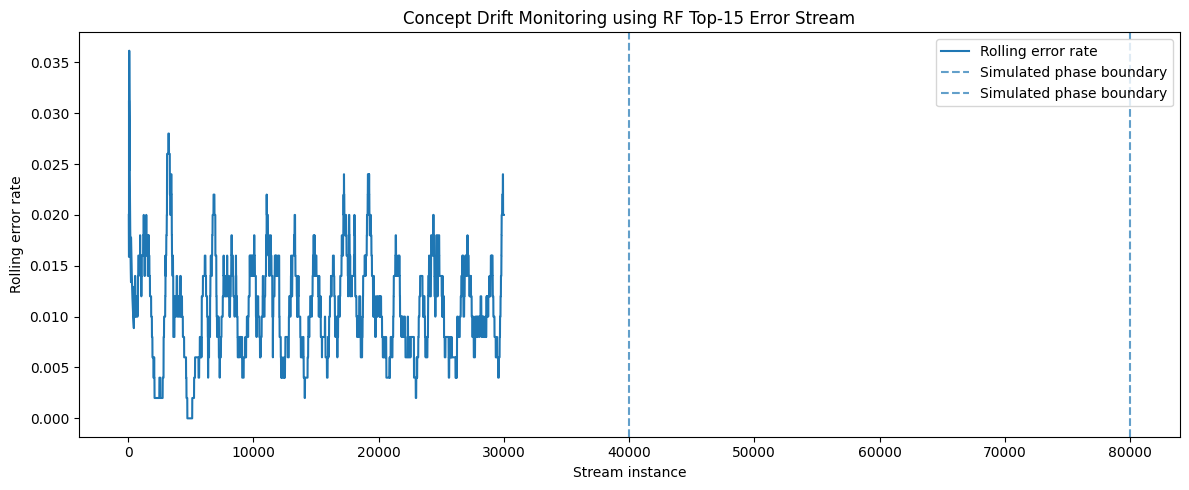

In [12]:
# ============================================================
# 9. Plot stream error rate and detected drift points
# ============================================================

error_series = pd.Series(errors)
rolling_error = error_series.rolling(window=500, min_periods=50).mean()

plt.figure(figsize=(12, 5))
plt.plot(rolling_error.values, label="Rolling error rate")

for boundary in phase_boundaries[:-1]:
    plt.axvline(boundary, linestyle="--", alpha=0.7, label="Simulated phase boundary")

for dp in drift_points[:20]:
    plt.axvline(dp, alpha=0.25)

plt.xlabel("Stream instance")
plt.ylabel("Rolling error rate")
plt.title("Concept Drift Monitoring using RF Top-15 Error Stream")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "rf_top15_drift_monitoring.png", dpi=300)
plt.show()

## Adaptive online IDS model

Random Forest is strong for static IDS, but it is not naturally incremental. For concept-drift-aware IDS, we also test an online learner using `SGDClassifier.partial_fit`. This gives a practical first adaptive baseline.

In [13]:
# ============================================================
# 10. Online adaptive IDS using SGDClassifier.partial_fit - FAST VERSION
# ============================================================

# IMPORTANT:
# This cell uses the same reduced stream used by the static RF cell:
# X_stream_small and y_stream_small.
# This keeps all arrays equal in length and prevents very long execution.

online_model = SGDClassifier(
    loss="log_loss",
    penalty="l2",
    alpha=0.0001,
    random_state=RANDOM_STATE
)

classes = np.array([0, 1])
online_model.partial_fit(X_train_15.values, y_train, classes=classes)

online_preds = []
online_errors = []
online_drift_points = []

if river_available:
    online_detector = drift.ADWIN(delta=0.002)
else:
    online_detector = FallbackWindowDriftDetector(window_size=500, threshold=0.08)

# Use small stream for fast execution
X_online_stream = X_stream_small.copy()
y_online_stream = np.array(y_stream_small)

start_time = time.time()

for i, (x_row, y_true) in enumerate(zip(X_online_stream.values, y_online_stream)):
    x_2d = x_row.reshape(1, -1)
    y_pred = int(online_model.predict(x_2d)[0])
    online_preds.append(y_pred)

    error = int(y_pred != y_true)
    online_errors.append(error)

    if river_available:
        online_detector.update(error)

        if hasattr(online_detector, "drift_detected"):
            drift_now = online_detector.drift_detected
        elif hasattr(online_detector, "change_detected"):
            drift_now = online_detector.change_detected
        else:
            drift_now = False
    else:
        online_detector.update(error)
        drift_now = online_detector.drift_detected

    if drift_now:
        online_drift_points.append(i)

    # Adaptive update after observing true label
    online_model.partial_fit(x_2d, np.array([y_true]), classes=classes)

online_time = time.time() - start_time

print("Online adaptive IDS results")
print("Stream samples used:", len(y_online_stream))
print("Execution time in seconds:", online_time)
print("Accuracy:", accuracy_score(y_online_stream, online_preds))
print("F1:", f1_score(y_online_stream, online_preds, zero_division=0))
print("Balanced Accuracy:", balanced_accuracy_score(y_online_stream, online_preds))
print("MCC:", matthews_corrcoef(y_online_stream, online_preds))
print("Detected drift points:", online_drift_points[:20])
print(classification_report(y_online_stream, online_preds, zero_division=0))
print(confusion_matrix(y_online_stream, online_preds))

joblib.dump(online_model, OUTPUT_DIR / "online_sgd_top15.joblib")

Online adaptive IDS results
Accuracy: 0.9815166666666667
F1: 0.9811928705886344
Balanced Accuracy: 0.9815166666666667
MCC: 0.9636047538899681
Detected drift points: []
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     60000
           1       1.00      0.96      0.98     60000

    accuracy                           0.98    120000
   macro avg       0.98      0.98      0.98    120000
weighted avg       0.98      0.98      0.98    120000

[[59924    76]
 [ 2142 57858]]


['G:\\IoT_IDS_Research\\outputs\\concept_drift\\online_sgd_top15.joblib']

In [15]:
# ============================================================
# 11. Compare static RF and adaptive online IDS on stream - final corrected version
# ============================================================

# Use exactly the same stream portion for both models.
y_eval = np.array(y_stream_small)

# Make sure all arrays have the same length.
min_len = min(len(y_eval), len(preds), len(online_preds))

y_eval_final = y_eval[:min_len]
preds_final = np.array(preds)[:min_len]
online_preds_final = np.array(online_preds)[:min_len]

print("Evaluation samples:", min_len)
print("y_eval length:", len(y_eval_final))
print("Static RF predictions length:", len(preds_final))
print("Adaptive online predictions length:", len(online_preds_final))

comparison = pd.DataFrame([
    {
        "Model": "Static RF Top-15",
        "Accuracy": accuracy_score(y_eval_final, preds_final),
        "Precision": precision_score(y_eval_final, preds_final, zero_division=0),
        "Recall": recall_score(y_eval_final, preds_final, zero_division=0),
        "F1": f1_score(y_eval_final, preds_final, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_eval_final, preds_final),
        "MCC": matthews_corrcoef(y_eval_final, preds_final),
        "Drift Points Detected": len(drift_points)
    },
    {
        "Model": "Adaptive Online SGD Top-15",
        "Accuracy": accuracy_score(y_eval_final, online_preds_final),
        "Precision": precision_score(y_eval_final, online_preds_final, zero_division=0),
        "Recall": recall_score(y_eval_final, online_preds_final, zero_division=0),
        "F1": f1_score(y_eval_final, online_preds_final, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_eval_final, online_preds_final),
        "MCC": matthews_corrcoef(y_eval_final, online_preds_final),
        "Drift Points Detected": len(online_drift_points)
    }
])

comparison.to_csv(OUTPUT_DIR / "concept_drift_model_comparison.csv", index=False)
comparison

Evaluation samples: 30000
y_eval length: 30000
Static RF predictions length: 30000
Adaptive online predictions length: 30000


,Model,Accuracy,Precision,Recall,F1,Balanced Accuracy,MCC,Drift Points Detected
0,Static RF Top-15,0.989000,0.998909,0.979012,0.988860,0.988974,0.978192,0
1,Adaptive Online SGD Top-15,0.981633,0.998616,0.964508,0.981266,0.981589,0.963823,0


In [19]:
# ============================================================
# 12. Save experiment summary - corrected safe version
# ============================================================

summary_path = OUTPUT_DIR / "concept_drift_summary.txt"

with open(summary_path, "w", encoding="utf-8") as f:
    f.write("Concept Drift IDS Experiment Summary\n")
    f.write("====================================\n\n")
    
    f.write(f"Source mode: {source_mode}\n")
    f.write(f"Top features: {top_15_features}\n")
    
    # Use the evaluated stream length, not always full y_stream
    if "y_stream_small" in globals():
        f.write(f"Stream samples used for evaluation: {len(y_stream_small)}\n")
    else:
        f.write(f"Stream samples used for evaluation: {len(y_stream)}\n")
    
    f.write(f"Phase boundaries: {phase_boundaries}\n\n")
    
    f.write("Model Comparison:\n")
    f.write("-----------------\n")
    f.write(comparison.to_string(index=False))
    f.write("\n\n")
    
    if "drift_points" in globals():
        f.write(f"Static RF drift points detected: {len(drift_points)}\n")
        f.write(f"First 20 static drift points: {drift_points[:20]}\n\n")
    
    if "online_drift_points" in globals():
        f.write(f"Adaptive online drift points detected: {len(online_drift_points)}\n")
        f.write(f"First 20 adaptive drift points: {online_drift_points[:20]}\n\n")

comparison.to_csv(OUTPUT_DIR / "concept_drift_model_comparison.csv", index=False)

print("Saved:", summary_path)
print("Saved comparison:", OUTPUT_DIR / "concept_drift_model_comparison.csv")

if (OUTPUT_DIR / "rf_top15_drift_monitoring.png").exists():
    print("Saved plot:", OUTPUT_DIR / "rf_top15_drift_monitoring.png")
else:
    print("Plot file not found yet. Run the plotting cell if needed.")

Saved: G:\IoT_IDS_Research\outputs\concept_drift\concept_drift_summary.txt
Saved comparison: G:\IoT_IDS_Research\outputs\concept_drift\concept_drift_model_comparison.csv
Saved plot: G:\IoT_IDS_Research\outputs\concept_drift\rf_top15_drift_monitoring.png


## How to report this experiment

Use this notebook as the first concept-drift experiment. In the paper, describe it carefully as a **controlled drift simulation** over the balanced CICIoT2023 sample.

Recommended wording:

> To evaluate adaptive behavior, a stream-based experiment was constructed using the balanced CICIoT2023 test partition. Controlled covariate shifts were introduced across sequential phases to emulate evolving IoT traffic patterns. A drift detector monitored the prediction-error stream, while an online learner was evaluated as an adaptive baseline.

Next research upgrade: use timestamp/order information from raw files if available and create a more realistic chronological stream.